<a href="https://colab.research.google.com/github/justinrodriguezhotmailcom-pixel/PIA-Modelado/blob/main/PIA_Modelado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

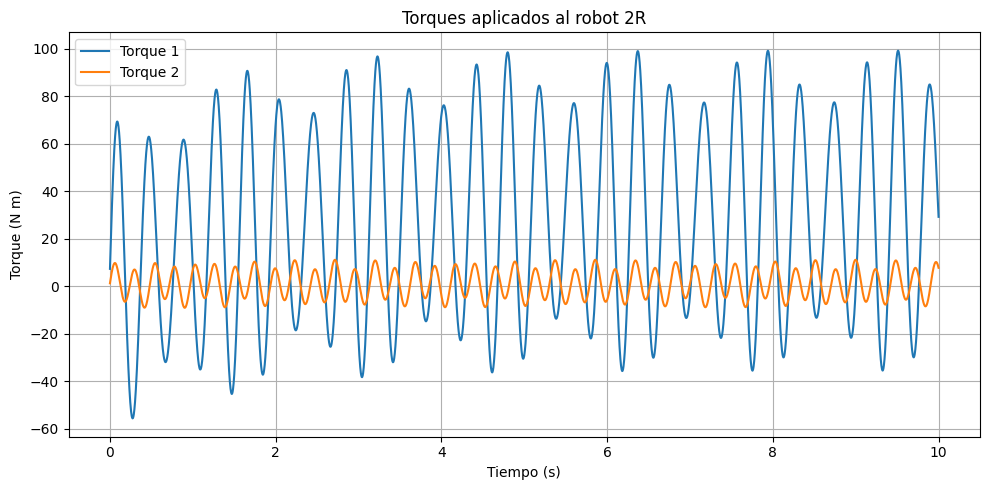

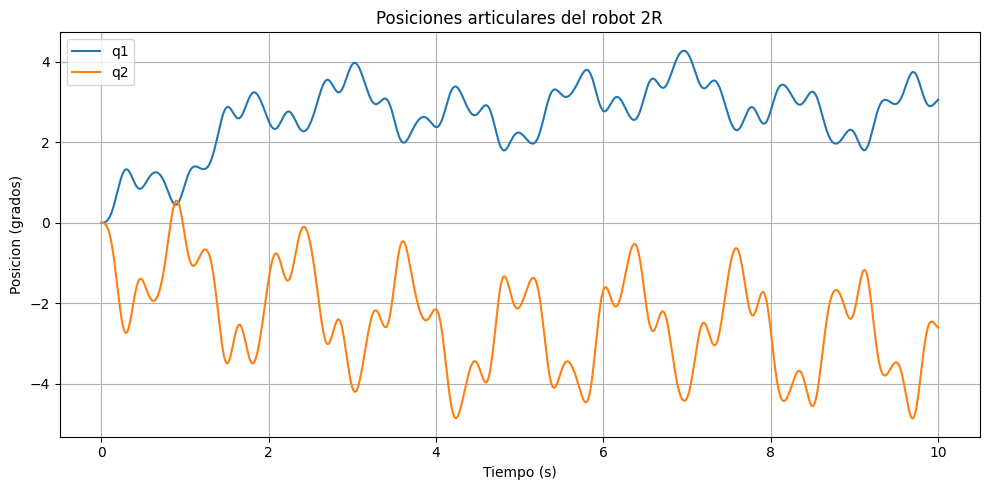

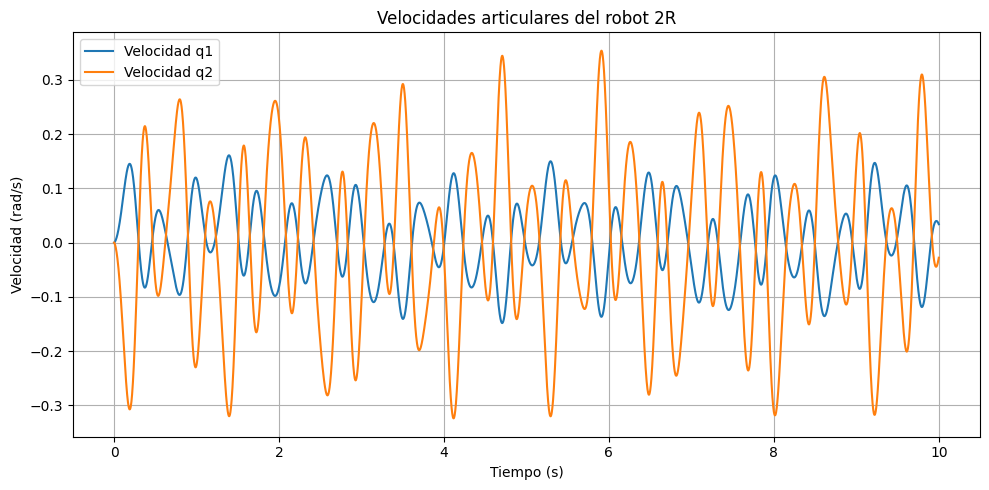

RESULTADOS DE SIMULACION
Tiempo final: 10.00 s
q1 final: 3.0557 grados
q2 final: -2.6046 grados
Velocidad q1 final: 0.033971 rad/s
Velocidad q2 final: -0.027904 rad/s
Numero de puntos: 4001
CONSTANTES DINAMICAS
a = 197.570800
b = 62.533300
h = 75.000000


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp



m1 = 20.0       # Masa del eslabon 1 (kg)
m2 = 10.0       # Masa del eslabon 2 (kg)

l1 = 3      # Longitud del eslabon 1 (m)
l2 = 5      # Longitud del eslabon 2 (m)

lc1 = 1.5    # Centro de masa del eslabon 1 (m)
lc2 = 2.5     # Centro de masa del eslabon 2 (m)

I1 = 0.0375     # Inercia del eslabon 1 (kg m^2)
I2 = 0.0333     # Inercia del eslabon 2 (kg m^2)

g = 9.81        # Gravedad (m/s^2)





B1 = 0.0
B2 = 0.0

Fc1 = 0.0
Fc2 = 0.0


a = m1*lc1**2 + I1 + I2 + m2*(l1**2 + lc2**2)
b = I2 + m2*lc2**2
h = m2*l1*lc2


def torques(t):

    tau1 = (
        32.0*(1 - np.exp(-0.8*t))
        + 56.0*np.sin(16*t + 0.1)
        + 12.0*np.sin(20*t + 0.15)
    )

    tau2 = (
        1.2*(1 - np.exp(-1.8*t))
        + 8.0*np.sin(26*t + 0.08)
        + 2.0*np.sin(12*t + 0.34)
    )

    return np.array([tau1, tau2])


def matriz_M(q):

    q2 = q[1]

    M = np.array([
        [a + 2*h*np.cos(q2), b + h*np.cos(q2)],
        [b + h*np.cos(q2),   b]
    ])

    return M

def matriz_C(q, qp):

    q2 = q[1]
    qp1 = qp[0]
    qp2 = qp[1]

    C = np.array([
        [-h*np.sin(q2)*qp2,
         -h*np.sin(q2)*(qp1 + qp2)],

        [h*np.sin(q2)*qp1,
         0.0]
    ])

    return C


def vector_gravedad(q):

    q1 = q[0]
    q2 = q[1]

    G = np.array([
        g*(m1*lc1 + m2*l1)*np.sin(q1)
        + m2*g*lc2*np.sin(q1 + q2),

        m2*g*lc2*np.sin(q1 + q2)
    ])

    return G


def vector_friccion(qp):

    F = np.array([
        B1*qp[0] + Fc1*np.sign(qp[0]),
        B2*qp[1] + Fc2*np.sign(qp[1])
    ])

    return F



def modelo_robot(t, x):

    # Variables de estado
    q = x[0:2]
    qp = x[2:4]

    # Calculo de matrices y vectores
    M = matriz_M(q)
    C = matriz_C(q, qp)
    G = vector_gravedad(q)
    F = vector_friccion(qp)

    # Torques aplicados
    tau = torques(t)

    # Aceleraciones articulares
    qpp = np.linalg.solve(
        M,
        tau - C @ qp - G - F
    )

    # Derivadas del estado
    dx = np.concatenate((qp, qpp))

    return dx


t_inicio = 0.0
t_final = 10.0
dt = 0.0025

tiempo = np.arange(t_inicio, t_final + dt/2, dt)

# Condiciones iniciales:
# q1 = 0, q2 = 0
# q1 punto = 0, q2 punto = 0

x0 = [0.0, 0.0, 0.0, 0.0]


sol = solve_ivp(
    modelo_robot,
    (t_inicio, t_final),
    x0,
    method='RK45',
    t_eval=tiempo,
    rtol=1e-8,
    atol=1e-10
)

if not sol.success:
    raise RuntimeError(sol.message)



q1 = sol.y[0]
q2 = sol.y[1]

qp1 = sol.y[2]
qp2 = sol.y[3]

# Conversion de radianes a grados
q1_grados = np.rad2deg(q1)
q2_grados = np.rad2deg(q2)

# Calculo de torques para graficar
tau_resultados = np.array([torques(t) for t in sol.t])

tau1 = tau_resultados[:, 0]
tau2 = tau_resultados[:, 1]



plt.figure(figsize=(10, 5))
plt.plot(sol.t, tau1, label='Torque 1')
plt.plot(sol.t, tau2, label='Torque 2')
plt.title('Torques aplicados al robot 2R')
plt.xlabel('Tiempo (s)')
plt.ylabel('Torque (N m)')
plt.grid()
plt.legend()
plt.tight_layout()

plt.figure(figsize=(10, 5))
plt.plot(sol.t, q1_grados, label='q1')
plt.plot(sol.t, q2_grados, label='q2')
plt.title('Posiciones articulares del robot 2R')
plt.xlabel('Tiempo (s)')
plt.ylabel('Posicion (grados)')
plt.grid()
plt.legend()
plt.tight_layout()

plt.figure(figsize=(10, 5))
plt.plot(sol.t, qp1, label='Velocidad q1')
plt.plot(sol.t, qp2, label='Velocidad q2')
plt.title('Velocidades articulares del robot 2R')
plt.xlabel('Tiempo (s)')
plt.ylabel('Velocidad (rad/s)')
plt.grid()
plt.legend()
plt.tight_layout()

plt.show()


print("RESULTADOS DE SIMULACION")

print(f"Tiempo final: {sol.t[-1]:.2f} s")

print(f"q1 final: {q1_grados[-1]:.4f} grados")
print(f"q2 final: {q2_grados[-1]:.4f} grados")

print(f"Velocidad q1 final: {qp1[-1]:.6f} rad/s")
print(f"Velocidad q2 final: {qp2[-1]:.6f} rad/s")

print(f"Numero de puntos: {len(sol.t)}")

print("CONSTANTES DINAMICAS")
print(f"a = {a:.6f}")
print(f"b = {b:.6f}")
print(f"h = {h:.6f}")
